Goal:
Check whether _systematic underestimation_ is an intrinsic property of Gamma maximum likelihood estimation (finite sample bias),
or caused by neural network architecture / optimization.

Approach:

1. Sample data from a known Gamma distribution
2. Fit Gamma parameters using classical MLE (SciPy)
3. Repeat many times (Monte Carlo)
4. Inspect bias as a function of sample size


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

np.random.seed(0)

In [ ]:
# True Gamma parameters
alpha_true = 2.0  # shape
beta_true = 3.0  # scale

true_mean = alpha_true * beta_true
true_var = alpha_true * beta_true**2

print(f"True mean: {true_mean:.2f}")
print(f"True variance: {true_var:.2f}")

True mean: 6.00
True variance: 18.00


In [ ]:
def fit_alpha_mu_mle(y):
    alpha_hat, loc_hat, scale_hat = gamma.fit(y, floc=0)  # loc=0!
    mu_hat = alpha_hat * scale_hat
    rate_hat = alpha_hat / mu_hat
    return alpha_hat, mu_hat, rate_hat


np.random.seed(0)
alpha_true = 2.0
mu_true = 6.0
rate_true = alpha_true / mu_true

y = gamma.rvs(a=alpha_true, scale=1 / rate_true, size=200)  # scale = 1/rate

alpha_hat, mu_hat, rate_hat = fit_alpha_mu_mle(y)
print("true:", alpha_true, mu_true, rate_true)
print("mle :", alpha_hat, mu_hat, rate_hat)

true: 2.0 6.0 0.3333333333333333
mle : 2.071650543609915 5.9007220874800375 0.3510842423854322


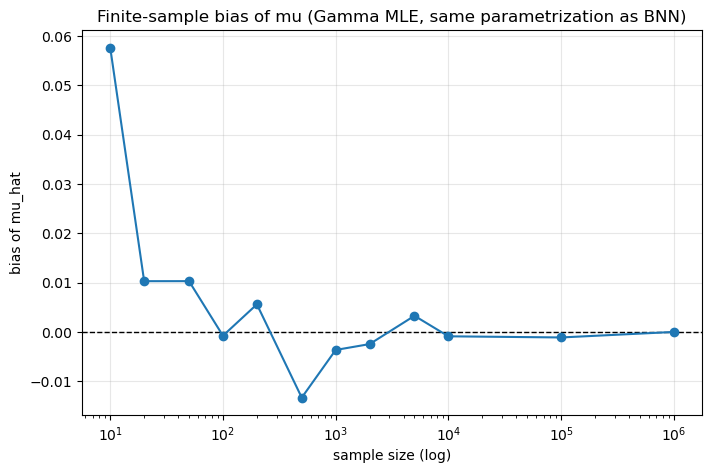

In [ ]:
alpha_true = 2.0
mu_true = 6.0
rate_true = alpha_true / mu_true

sample_sizes = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10_000, 100_000, 1_000_000]
n_mc = 1000

mu_means = []
mu_bias = []

for n in sample_sizes:
    mu_hats = []
    for _ in range(n_mc):
        y = gamma.rvs(a=alpha_true, scale=1 / rate_true, size=n)
        _, mu_hat, _ = fit_alpha_mu_mle(y)
        mu_hats.append(mu_hat)

    mu_mean = np.mean(mu_hats)
    mu_means.append(mu_mean)
    mu_bias.append(mu_mean - mu_true)

plt.figure(figsize=(8, 5))
plt.axhline(0, linestyle="--", linewidth=1, color="black")
plt.plot(sample_sizes, mu_bias, marker="o")
plt.xscale("log")
plt.xlabel("sample size (log)")
plt.ylabel("bias of mu_hat")
plt.title("Finite-sample bias of mu (Gamma MLE, same parametrization as BNN)")
plt.grid(True, alpha=0.3)
plt.show()

gamma visualization


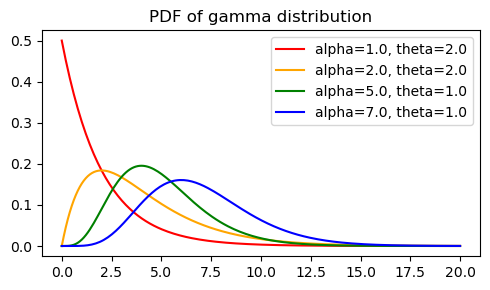

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

# x-range (start a tiny bit above 0 to avoid any numerical weirdness for k<1)
x = np.linspace(1e-4, 20, 200)

# (shape k, scale θ, color, label)
curves = [
    (1, 2.0, "red", "alpha=1.0, theta=2.0"),
    (2.0, 2.0, "orange", "alpha=2.0, theta=2.0"),
    (5.0, 1.0, "green", "alpha=5.0, theta=1.0"),
    (7.0, 1.0, "blue", "alpha=7.0, theta=1.0"),
]

fig, ax = plt.subplots(figsize=(5, 3))

# Plot gamma PDFs
for k, theta, color, label in curves:
    y = gamma.pdf(x, a=k, scale=theta)
    ax.plot(x, y, color=color, label=label)


# Legend (colored lines + labels); tweak if you want lines only
leg = ax.legend(
    frameon=True,
    loc="upper right",
)
plt.title("PDF of gamma distribution")
plt.tight_layout()
plt.show()

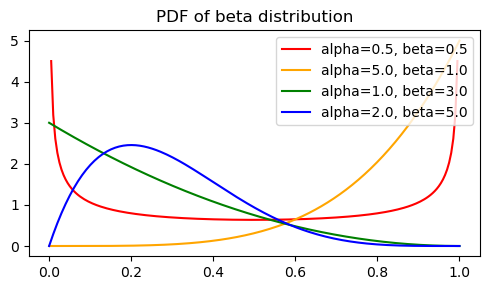

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# x-range (start a tiny bit above 0 to avoid any numerical weirdness for k<1)
x = np.linspace(0, 1, 200)

# (shape k, scale θ, color, label)
curves = [
    (0.5, 0.5, "red", "alpha=0.5, beta=0.5"),
    (5.0, 1.0, "orange", "alpha=5.0, beta=1.0"),
    (1.0, 3.0, "green", "alpha=1.0, beta=3.0"),
    (2.0, 5.0, "blue", "alpha=2.0, beta=5.0"),
]

fig, ax = plt.subplots(figsize=(5, 3))

# Plot gamma PDFs
for a, b, color, label in curves:
    y = beta.pdf(x, a=a, b=b)
    ax.plot(x, y, color=color, label=label)


# Legend (colored lines + labels); tweak if you want lines only
leg = ax.legend(
    frameon=True,
    loc="upper right",
)
plt.title("PDF of beta distribution")
plt.tight_layout()
plt.show()